In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Numpy:",np.__version__)
print("Pandas:",pd.__version__)
print("Scikit-learn:",sklearn.__version__)

Numpy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1


In [ ]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer(as_frame=True)
df = data.frame
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [ ]:
df.shape

(569, 31)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [ ]:
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [ ]:
df["target"].value_counts()

,count
target,
1,357
0,212


In [ ]:
print(data.target_names)

['malignant' 'benign']


In [ ]:
X = df.drop("target",axis=1)
y = df["target"]

print(X.shape)
print(y.shape)

(569, 30)
(569,)


In [ ]:
X.columns

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension'],
      dtype='object')

In [ ]:
X.isnull().sum()

,0
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


In [ ]:
X.isnull().sum().sum()

np.int64(0)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df[df.duplicated()]

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target


In [ ]:
y.value_counts()

,count
target,
1,357
0,212


In [ ]:
y.value_counts(normalize=True)*100

,proportion
target,
1,62.741652
0,37.258348


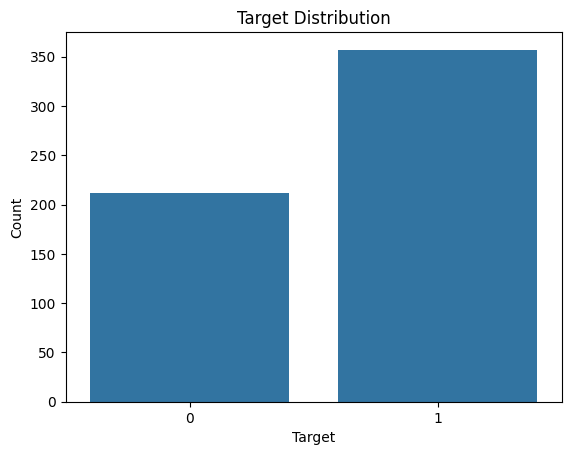

In [ ]:
sns.countplot(x=y)

plt.title("Target Distribution")
plt.xlabel("Target")
plt.ylabel("Count")
plt.show()

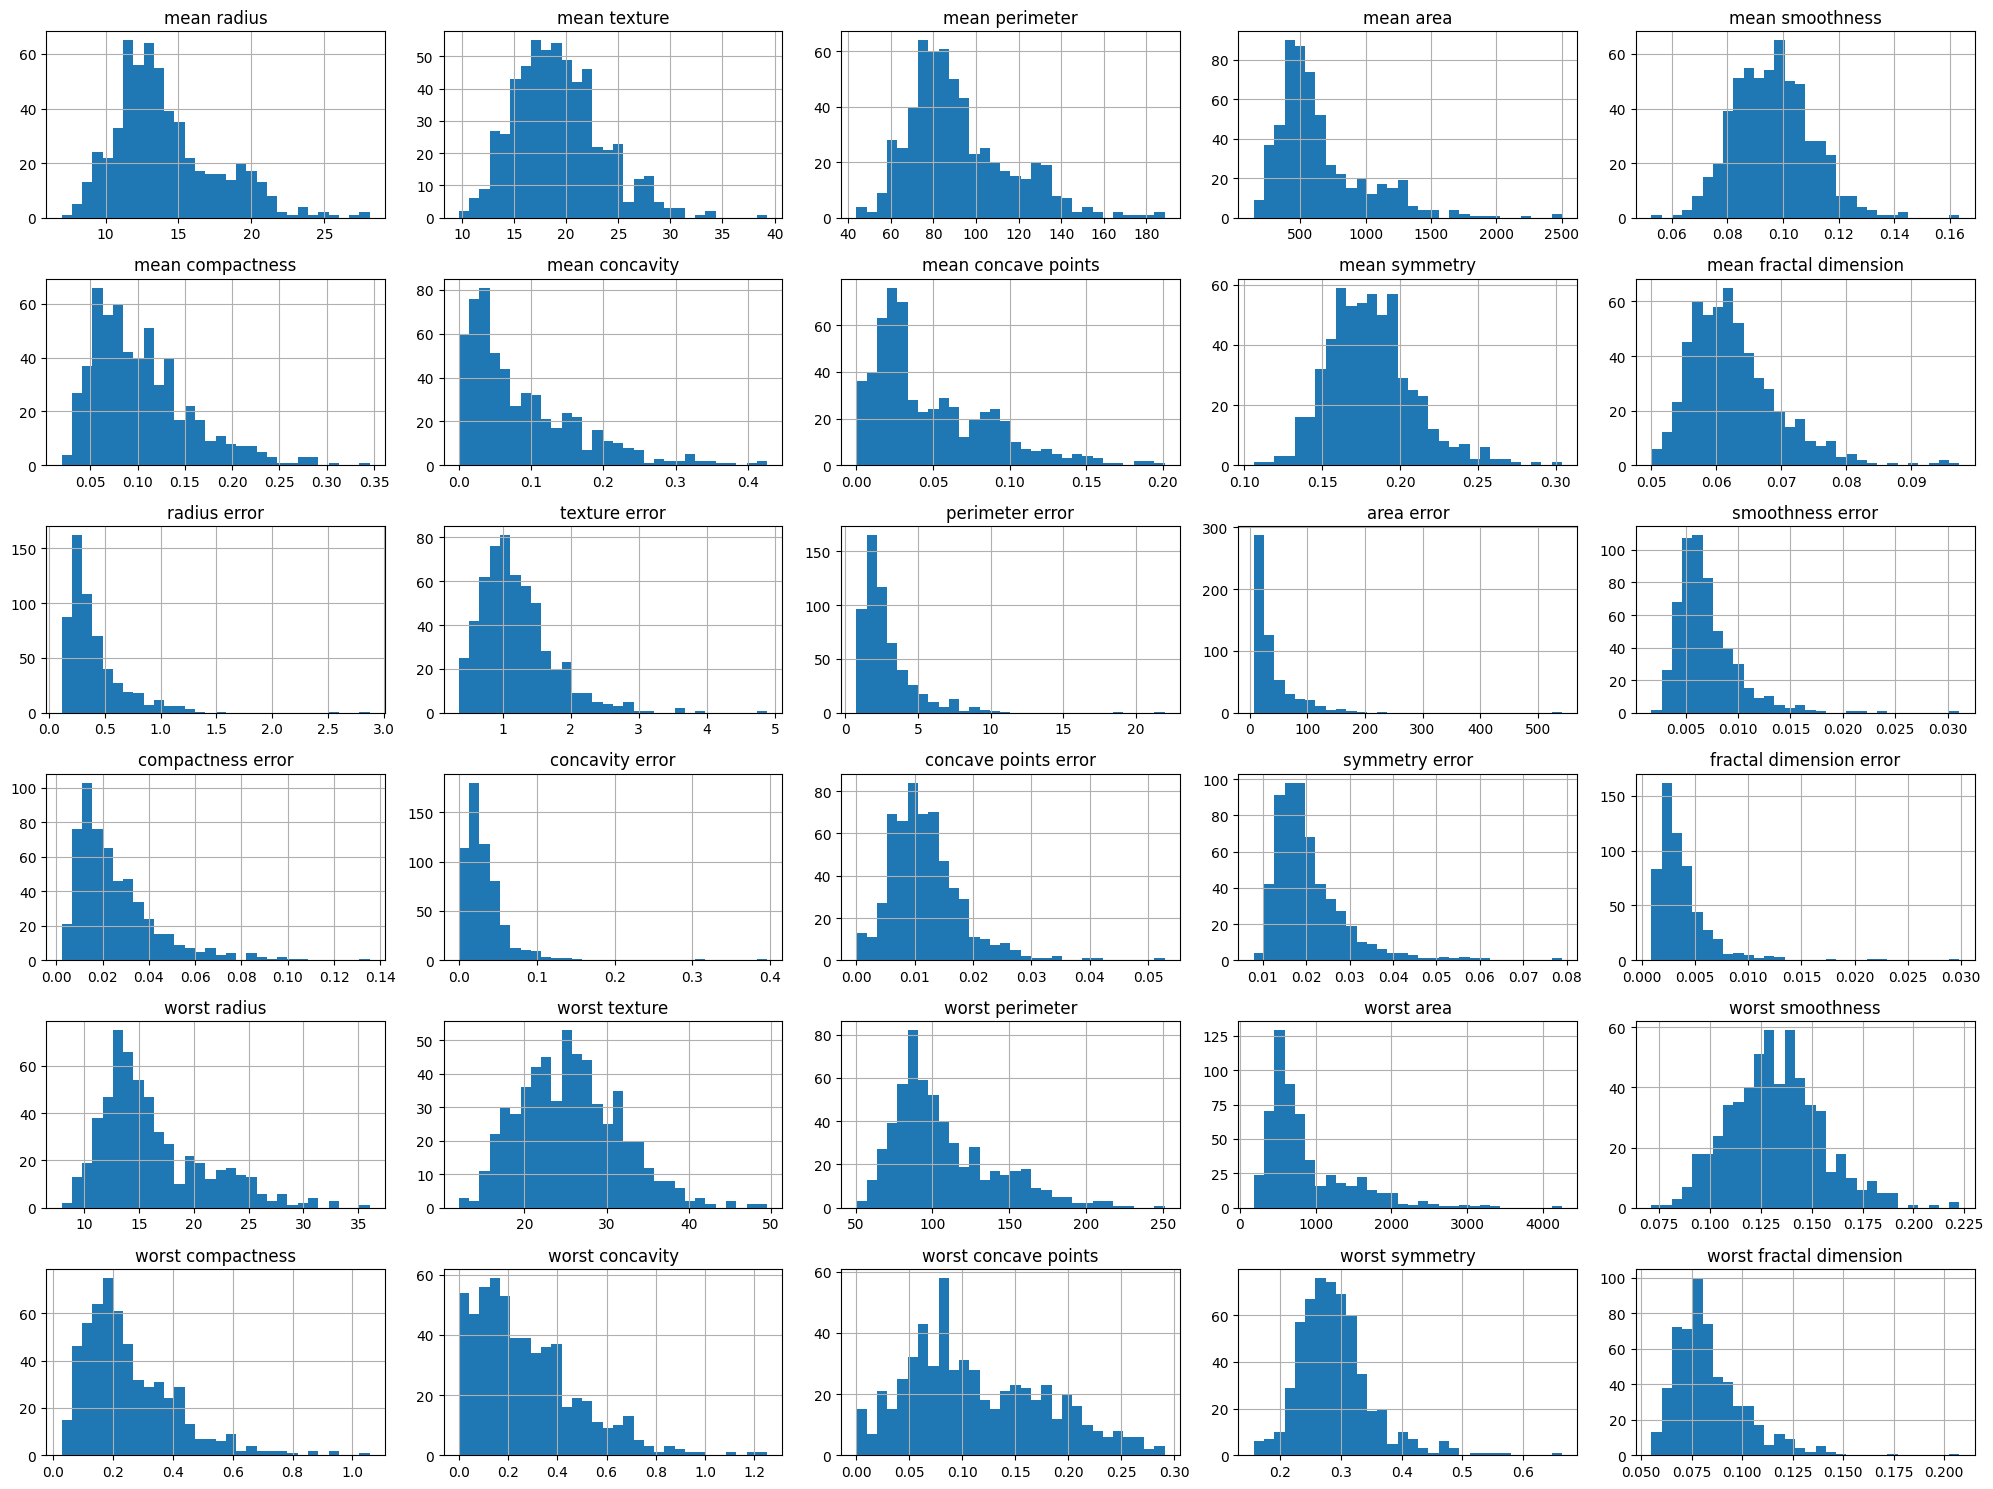

In [ ]:
X.hist(figsize=(20,15),bins=30)
plt.tight_layout()
plt.show()

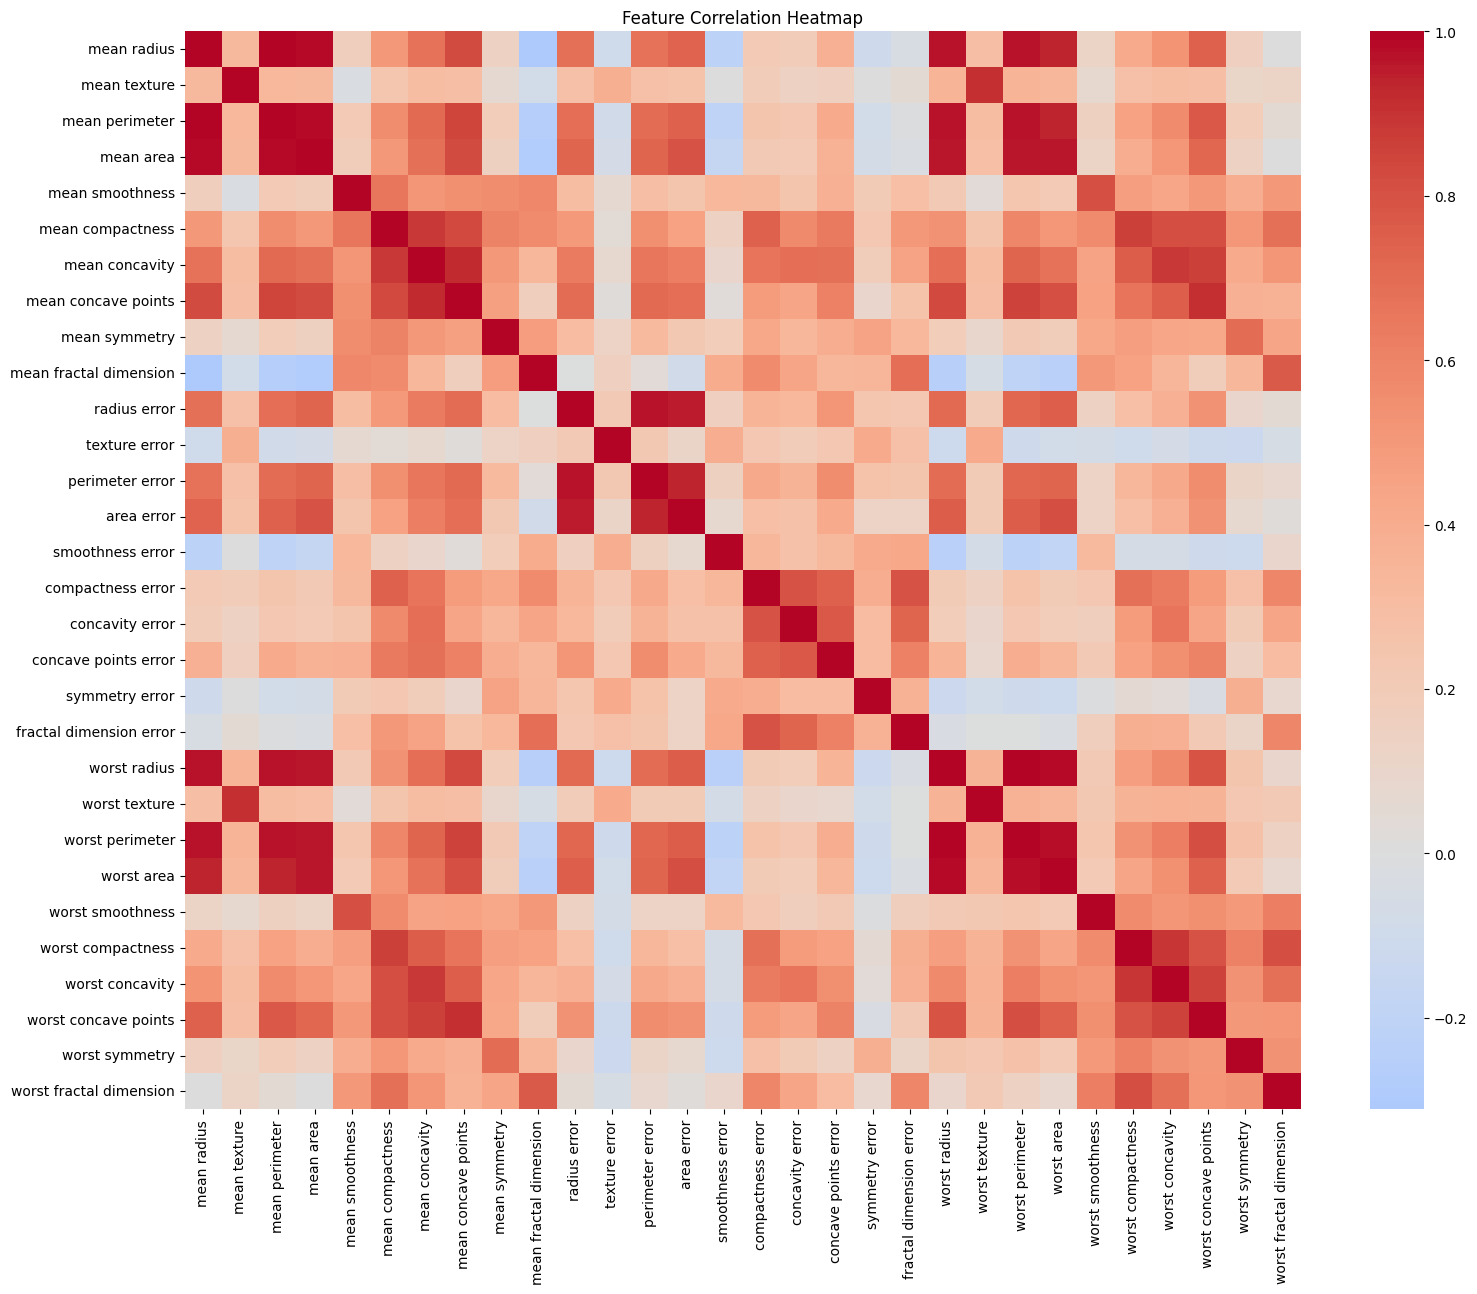

In [ ]:
plt.figure(figsize=(18,14))

sns.heatmap(
    X.corr(),
    cmap="coolwarm",
    center=0
)
plt.title("Feature Correlation Heatmap")
plt.show()

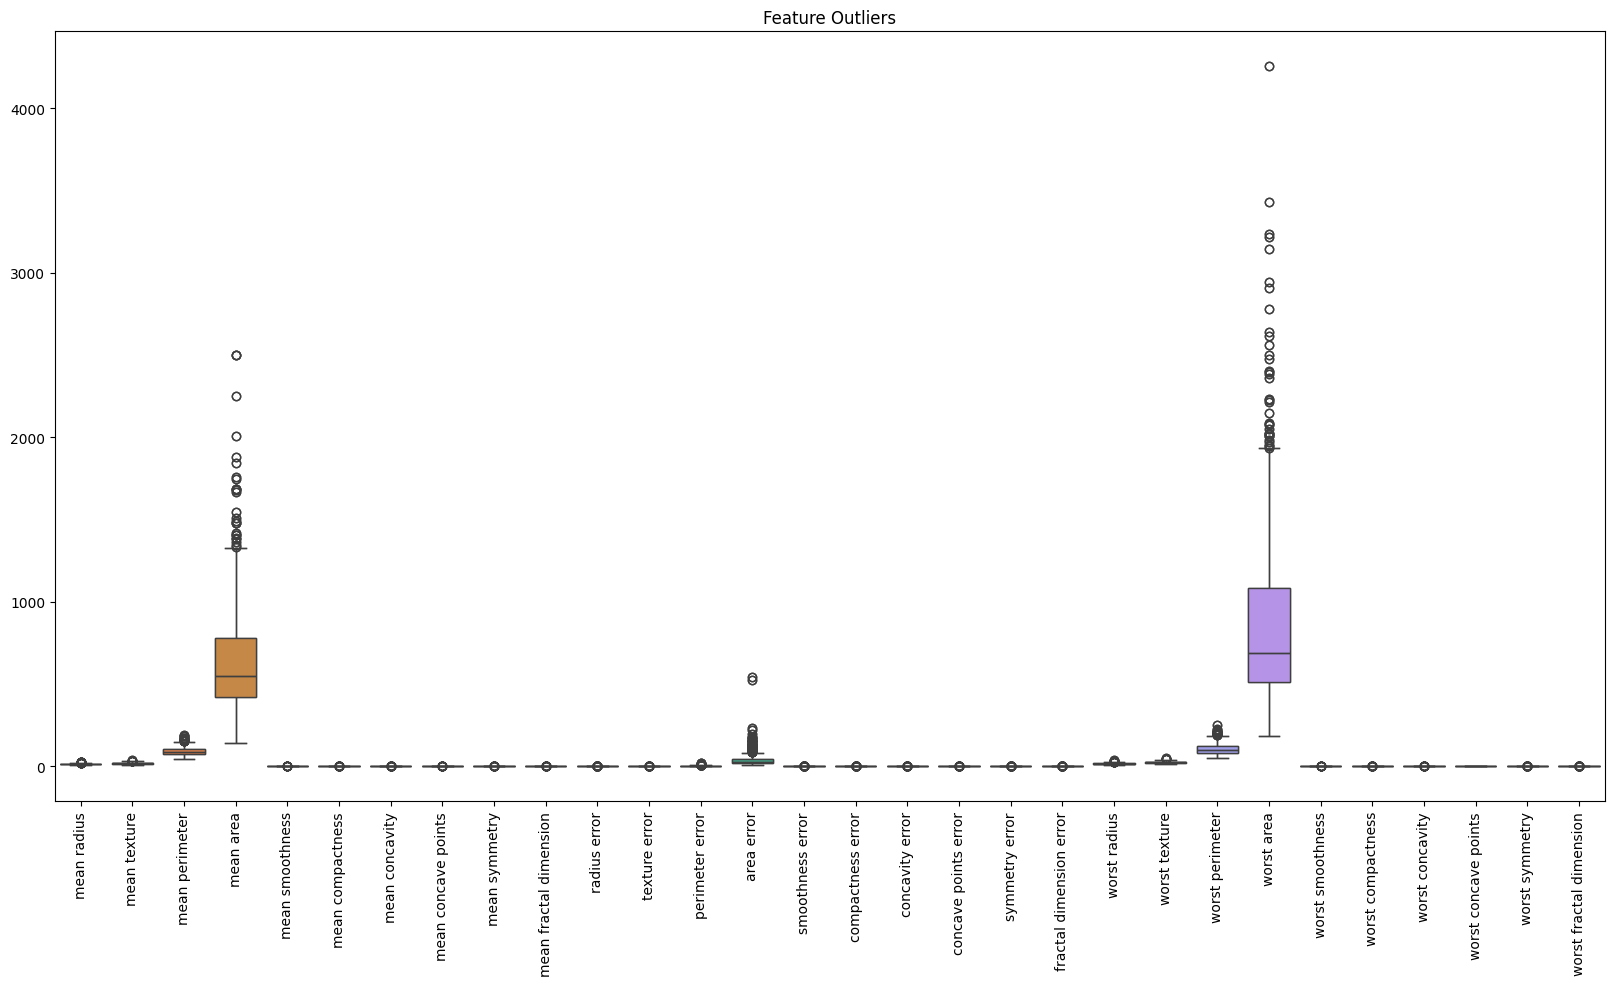

In [ ]:
plt.figure(figsize=(20, 10))
sns.boxplot(data=X)
plt.xticks(rotation=90)
sns.boxplot(data=X)
plt.xticks(rotation=90)
plt.title("Feature Outliers")
plt.show()

In [ ]:
X.describe().loc[["min","max"]].T

,min,max
mean radius,6.981000,28.11000
mean texture,9.710000,39.28000
mean perimeter,43.790000,188.50000
mean area,143.500000,2501.00000
mean smoothness,0.052630,0.16340
mean compactness,0.019380,0.34540
mean concavity,0.000000,0.42680
mean concave points,0.000000,0.20120
mean symmetry,0.106000,0.30400
mean fractal dimension,0.049960,0.09744


In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_temp,y_train,y_temp= train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [ ]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [ ]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (398, 30)
Validation: (85, 30)
Testing: (86, 30)


In [ ]:
#Logistic Regression

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000))
])

In [ ]:
baseline_model.fit(X_train, y_train)
y_pred = baseline_model.predict(X_val)

In [ ]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_val,y_pred)
print(accuracy)

0.9882352941176471


In [ ]:
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

print(y_train.shape)
print(y_val.shape)
print(y_test.shape)

(398, 30)
(85, 30)
(86, 30)
(398,)
(85,)
(86,)


In [ ]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)
X_test_imputed = imputer.transform(X_test)

In [ ]:
SimpleImputer(strategy="mean")
SimpleImputer(strategy="median")
SimpleImputer(
    strategy="constant",
    fill_value=0
)

SimpleImputer(fill_value=0, strategy='constant')

In [ ]:
X_train_fe = X_train.copy()
X_val_fe = X_val.copy()
X_test_fe = X_test.copy()

In [ ]:
for data in [X_train_fe, X_val_fe, X_test_fe]:

    data["radius_perimeter_ratio"] = (
        data["mean radius"] / data["mean perimeter"]
    )

    data["area_perimeter_ratio"] = (
        data["mean area"] / data["mean perimeter"]
    )

    data["texture_smoothness_ratio"] = (
        data["mean texture"] / data["mean smoothness"]
    )

In [ ]:
print(X_train_fe.shape)

(398, 33)


In [ ]:
mean_value = X.mean()

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_fe)

X_val_scaled = scaler.transform(X_val_fe)

X_test_scaled = scaler.transform(X_test_fe)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_fe)

X_val_scaled = scaler.transform(X_val_fe)

X_test_scaled = scaler.transform(X_test_fe)

In [ ]:
scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train_fe.columns
)

scaled_df.describe().T.head()

,count,mean,std,min,25%,50%,75%,max
mean radius,398.0,-4.039203e-16,1.001259,-2.040889,-0.697626,-0.234952,0.481656,3.338761
mean texture,398.0,3.637515e-16,1.001259,-2.142817,-0.745647,-0.114918,0.554189,4.435897
mean perimeter,398.0,-3.146562e-16,1.001259,-1.993413,-0.698873,-0.235459,0.498304,3.432734
mean area,398.0,6.248491e-17,1.001259,-1.492594,-0.687575,-0.314047,0.372545,3.999253
mean smoothness,398.0,1.673703e-16,1.001259,-2.496138,-0.741565,-0.058825,0.672107,3.503575


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000))
])

In [ ]:
logistic_pipeline.fit(X_train, y_train)
y_val_pred = logistic_pipeline.predict(X_val)

In [ ]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    logistic_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("CV Scores:", cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())
print("Std:", cv_scores.std())


CV Scores: [0.9875     0.95       0.9875     0.98734177 0.98734177]
Mean CV Accuracy: 0.9799367088607595
Std: 0.014968521689327005


In [ ]:
from sklearn.metrics import confusion_matrix

y_val_pred = logistic_pipeline.predict(X_val)

cm = confusion_matrix(y_val, y_val_pred)

print(cm)

[[32  0]
 [ 1 52]]


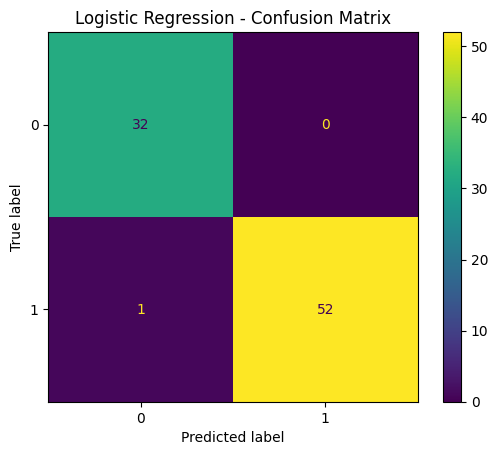

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [ ]:
y_val_prob = logistic_pipeline.predict_proba(X_val)[:, 1]

In [ ]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(
    y_val,
    y_val_prob
)

print("ROC-AUC:", roc_auc)

ROC-AUC: 1.0


In [ ]:
from sklearn.metrics import average_precision_score

pr_auc = average_precision_score(
    y_val,
    y_val_prob
)

print("PR-AUC:", pr_auc)

PR-AUC: 1.0


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def evaluate_model(model, X_data, y_data):

    predictions = model.predict(X_data)
    probabilities = model.predict_proba(X_data)[:, 1]

    print("Accuracy :", accuracy_score(y_data, predictions))
    print("Precision:", precision_score(y_data, predictions))
    print("Recall   :", recall_score(y_data, predictions))
    print("F1 Score :", f1_score(y_data, predictions))
    print("ROC-AUC  :", roc_auc_score(y_data, probabilities))

In [ ]:
evaluate_model(
    logistic_pipeline,
    X_val,
    y_val
)

Accuracy : 0.9882352941176471
Precision: 1.0
Recall   : 0.9811320754716981
F1 Score : 0.9904761904761905
ROC-AUC  : 1.0


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000))
])

logistic_model.fit(X_train, y_train)
evaluate_model(logistic_model, X_val, y_val)

Accuracy : 0.9882352941176471
Precision: 1.0
Recall   : 0.9811320754716981
F1 Score : 0.9904761904761905
ROC-AUC  : 1.0


In [ ]:
#KNN
from sklearn.neighbors import KNeighborsClassifier

knn_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)

evaluate_model(knn_model, X_val, y_val)

Accuracy : 0.9882352941176471
Precision: 0.9814814814814815
Recall   : 1.0
F1 Score : 0.9906542056074766
ROC-AUC  : 0.9955778301886793


In [ ]:
#Naive Bayes
from sklearn.naive_bayes import GaussianNB

nb_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", GaussianNB())
])

nb_model.fit(X_train, y_train)

evaluate_model(nb_model, X_val, y_val)

Accuracy : 0.9647058823529412
Precision: 0.9807692307692307
Recall   : 0.9622641509433962
F1 Score : 0.9714285714285714
ROC-AUC  : 0.9976415094339622


In [ ]:
#Decison Tree
from sklearn.tree import DecisionTreeClassifier

tree_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(
        random_state=42
    ))
])

tree_model.fit(X_train, y_train)

evaluate_model(tree_model, X_val, y_val)

Accuracy : 0.9294117647058824
Precision: 0.9795918367346939
Recall   : 0.9056603773584906
F1 Score : 0.9411764705882353
ROC-AUC  : 0.9372051886792453


In [ ]:
#Random Forest
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

evaluate_model(rf_model, X_val, y_val)

Accuracy : 0.9882352941176471
Precision: 1.0
Recall   : 0.9811320754716981
F1 Score : 0.9904761904761905
ROC-AUC  : 1.0


In [ ]:
#SVM
from sklearn.svm import SVC

svm_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SVC(
        probability=True,
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)

evaluate_model(svm_model, X_val, y_val)

Accuracy : 0.9764705882352941
Precision: 1.0
Recall   : 0.9622641509433962
F1 Score : 0.9807692307692307
ROC-AUC  : 1.0


In [ ]:
#Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier

gb_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GradientBoostingClassifier(
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)

evaluate_model(gb_model, X_val, y_val)

Accuracy : 0.9764705882352941
Precision: 0.9811320754716981
Recall   : 0.9811320754716981
F1 Score : 0.9811320754716981
ROC-AUC  : 0.9994103773584906


In [ ]:
!pip install -q xgboost

In [ ]:
from xgboost import XGBClassifier

xgb_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        random_state=42,
        eval_metric="logloss"
    ))
])

xgb_model.fit(X_train, y_train)

evaluate_model(xgb_model, X_val, y_val)

Accuracy : 0.9882352941176471
Precision: 0.9814814814814815
Recall   : 1.0
F1 Score : 0.9906542056074766
ROC-AUC  : 1.0


In [ ]:
!pip install -q lightgbm

In [ ]:
from lightgbm import LGBMClassifier

lgbm_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=-1,
        random_state=42,
        verbosity=-1
    ))
])

lgbm_model.fit(X_train, y_train)

evaluate_model(lgbm_model, X_val, y_val)

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0
ROC-AUC  : 1.0


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [ ]:
!pip install -q catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.6 MB/s eta 0:00:00


In [ ]:
from catboost import CatBoostClassifier

cat_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", CatBoostClassifier(
        iterations=300,
        learning_rate=0.05,
        depth=5,
        verbose=False,
        random_seed=42
    ))
])

cat_model.fit(X_train, y_train)

evaluate_model(cat_model, X_val, y_val)

Accuracy : 0.9882352941176471
Precision: 0.9814814814814815
Recall   : 1.0
F1 Score : 0.9906542056074766
ROC-AUC  : 1.0


In [ ]:
models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "Naive Bayes": nb_model,
    "Decision Tree": tree_model,
    "Random Forest": rf_model,
    "SVM": svm_model,
    "Gradient Boosting": gb_model,
    "XGBoost": xgb_model,
    "LightGBM": lgbm_model,
    "CatBoost": cat_model
}

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, model in models.items():

    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1": f1_score(y_val, predictions),
        "ROC-AUC": roc_auc_score(y_val, probabilities)
    })

results_df = pd.DataFrame(results)

results_df.sort_values(
    "F1",
    ascending=False
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
8,LightGBM,1.000000,1.000000,1.000000,1.000000,1.000000
1,KNN,0.988235,0.981481,1.000000,0.990654,0.995578
9,CatBoost,0.988235,0.981481,1.000000,0.990654,1.000000
7,XGBoost,0.988235,0.981481,1.000000,0.990654,1.000000
0,Logistic Regression,0.988235,1.000000,0.981132,0.990476,1.000000
4,Random Forest,0.988235,1.000000,0.981132,0.990476,1.000000
6,Gradient Boosting,0.976471,0.981132,0.981132,0.981132,0.999410
5,SVM,0.976471,1.000000,0.962264,0.980769,1.000000
2,Naive Bayes,0.964706,0.980769,0.962264,0.971429,0.997642
3,Decision Tree,0.929412,0.979592,0.905660,0.941176,0.937205


In [ ]:
#cross validation comparison
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, model in models.items():

    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1": f1_score(y_val, predictions),
        "ROC-AUC": roc_auc_score(y_val, probabilities)
    })

results_df = pd.DataFrame(results)

results_df.sort_values(
    "F1",
    ascending=False
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
8,LightGBM,1.000000,1.000000,1.000000,1.000000,1.000000
1,KNN,0.988235,0.981481,1.000000,0.990654,0.995578
9,CatBoost,0.988235,0.981481,1.000000,0.990654,1.000000
7,XGBoost,0.988235,0.981481,1.000000,0.990654,1.000000
0,Logistic Regression,0.988235,1.000000,0.981132,0.990476,1.000000
4,Random Forest,0.988235,1.000000,0.981132,0.990476,1.000000
6,Gradient Boosting,0.976471,0.981132,0.981132,0.981132,0.999410
5,SVM,0.976471,1.000000,0.962264,0.980769,1.000000
2,Naive Bayes,0.964706,0.980769,0.962264,0.971429,0.997642
3,Decision Tree,0.929412,0.979592,0.905660,0.941176,0.937205


In [ ]:
from sklearn.ensemble import BaggingClassifier

bagging_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", BaggingClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

bagging_model.fit(X_train, y_train)

evaluate_model(bagging_model,X_val,y_val
)

Accuracy : 0.9882352941176471
Precision: 1.0
Recall   : 0.9811320754716981
F1 Score : 0.9904761904761905
ROC-AUC  : 0.9994103773584906


In [ ]:
from sklearn.ensemble import StackingClassifier

stacking_model = StackingClassifier(
    estimators=[
        ("lr", logistic_model),
        ("rf", rf_model),
        ("svm", svm_model)
    ],
    final_estimator=LogisticRegression(max_iter=5000)
)

In [ ]:
stacking_model.fit(X_train, y_train)
evaluate_model(
    stacking_model,X_val,y_val
)

Accuracy : 0.9882352941176471
Precision: 1.0
Recall   : 0.9811320754716981
F1 Score : 0.9904761904761905
ROC-AUC  : 1.0


In [ ]:
deep_tree = DecisionTreeClassifier(
    random_state=42
)

deep_tree.fit(X_train, y_train)

train_acc = deep_tree.score(X_train, y_train)
val_acc = deep_tree.score(X_val, y_val)

print("Train:", train_acc)
print("Validation:", val_acc)

Train: 1.0
Validation: 0.9294117647058824


In [ ]:
small_tree = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

small_tree.fit(X_train, y_train)

print("Train:", small_tree.score(X_train, y_train))
print("Validation:", small_tree.score(X_val, y_val))

Train: 0.9271356783919598
Validation: 0.9529411764705882


In [ ]:
lr_l2 = LogisticRegression(
    C=1.0,
    penalty="l2",
    max_iter=5000
)

In [ ]:
for c in [0.01, 0.1, 1, 10, 100]:

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LogisticRegression(
            C=c,
            max_iter=5000
        ))
    ])

    model.fit(X_train, y_train)

    print(
        c,
        model.score(X_train, y_train),
        model.score(X_val, y_val)
    )

0.01 0.9597989949748744 0.9647058823529412
0.1 0.9849246231155779 0.9882352941176471
1 0.9874371859296482 0.9882352941176471
10 0.9899497487437185 0.9882352941176471
100 0.9949748743718593 0.9647058823529412


In [ ]:
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_split": [2, 5]
}

In [ ]:
grid_search = GridSearchCV(
    rf_pipeline,
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('imputer',
                                        SimpleImputer(strategy='median')),
                                       ('model',
                                        RandomForestClassifier(n_jobs=-1,
                                                               random_state=42))]),
             n_jobs=-1,
             param_grid={'model__max_depth': [None, 5, 10],
                         'model__min_samples_split': [2, 5],
                         'model__n_estimators': [100, 200]},
             scoring='f1')

In [ ]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 100}
0.978097809780978


In [ ]:
best_rf = grid_search.best_estimator_

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

In [ ]:
random_search = RandomizedSearchCV(
    rf_pipeline,
    param_distributions,
    n_iter=15,
    cv=5,
    scoring="f1",
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('imputer',
                                              SimpleImputer(strategy='median')),
                                             ('model',
                                              RandomForestClassifier(n_jobs=-1,
                                                                     random_state=42))]),
                   n_iter=15, n_jobs=-1,
                   param_distributions={'model__max_depth': [None, 5, 10, 15,
                                                             20],
                                        'model__min_samples_leaf': [1, 2, 4],
                                        'model__min_samples_split': [2, 5, 10],
                                        'model__n_estimators': [100, 200, 300,
                                                                500]},
                   random_state=42, scoring='f1')

In [ ]:
print(random_search.best_params_)
print(random_search.best_score_)

{'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_depth': 20}
0.9761176117611761


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)
X_val_pca = pca.transform(X_val_scaled)
print(X_train_pca.shape)

(398, 2)


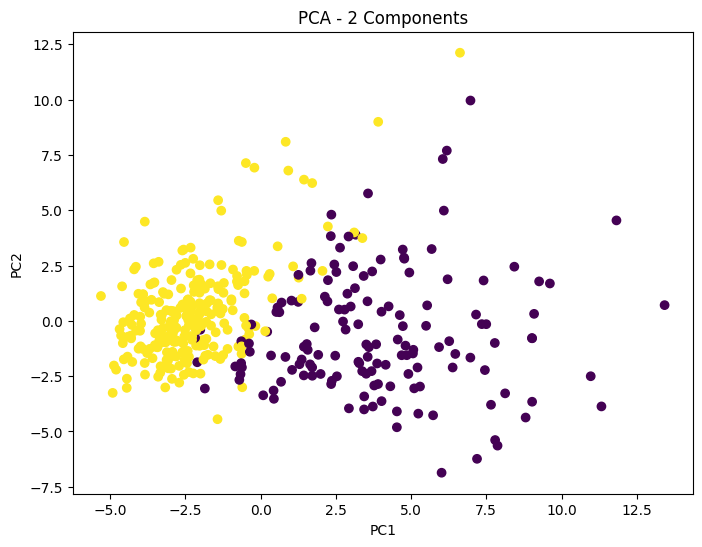

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA - 2 Components")

plt.show()

In [ ]:
print(pca.explained_variance_ratio_)
print(
    "Total explained variance:",
    pca.explained_variance_ratio_.sum()
)

[0.45156229 0.19628669]
Total explained variance: 0.6478489770033


In [ ]:
X_unsupervised = X.copy()
unsupervised_scaler = StandardScaler()

X_scaled = unsupervised_scaler.fit_transform(
    X_unsupervised
)

In [ ]:
#K-Means
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

print(clusters[:20])

[1 1 1 1 1 1 1 1 1 1 0 1 1 0 1 1 0 1 1 0]


In [ ]:
from sklearn.cluster import AgglomerativeClustering

hierarchical = AgglomerativeClustering(
    n_clusters=2
)

hierarchical_clusters = hierarchical.fit_predict(
    X_scaled
)

print(hierarchical_clusters[:20])

[0 0 0 0 0 0 0 0 0 0 1 1 0 1 0 0 1 0 0 1]


In [ ]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=1.5,
    min_samples=5
)

dbscan_clusters = dbscan.fit_predict(X_scaled)

print(
    np.unique(dbscan_clusters)
)

[-1  0]


In [ ]:
final_model = random_search.best_estimator_

In [ ]:
final_model.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('model',
                 RandomForestClassifier(max_depth=20, min_samples_split=10,
                                        n_estimators=200, n_jobs=-1,
                                        random_state=42))])

In [ ]:
evaluate_model(
    final_model,
    X_val,
    y_val
)

Accuracy : 0.9764705882352941
Precision: 1.0
Recall   : 0.9622641509433962
F1 Score : 0.9807692307692307
ROC-AUC  : 1.0


In [ ]:
test_predictions = final_model.predict(X_test)

test_probabilities = (
    final_model.predict_proba(X_test)[:, 1]
)

In [ ]:
print(
    "Accuracy:",
    accuracy_score(y_test, test_predictions)
)

print(
    "Precision:",
    precision_score(y_test, test_predictions)
)

print(
    "Recall:",
    recall_score(y_test, test_predictions)
)

print(
    "F1:",
    f1_score(y_test, test_predictions)
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        test_probabilities
    )
)

Accuracy: 0.8837209302325582
Precision: 0.8928571428571429
Recall: 0.9259259259259259
F1: 0.9090909090909091
ROC-AUC: 0.9791666666666666


In [ ]:
rf = final_model.named_steps["model"]

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

importance.head(15)

,Feature,Importance
22,worst perimeter,0.149101
23,worst area,0.139078
27,worst concave points,0.125713
20,worst radius,0.081124
7,mean concave points,0.080180
0,mean radius,0.067296
2,mean perimeter,0.057039
3,mean area,0.049975
6,mean concavity,0.048759
26,worst concavity,0.036091


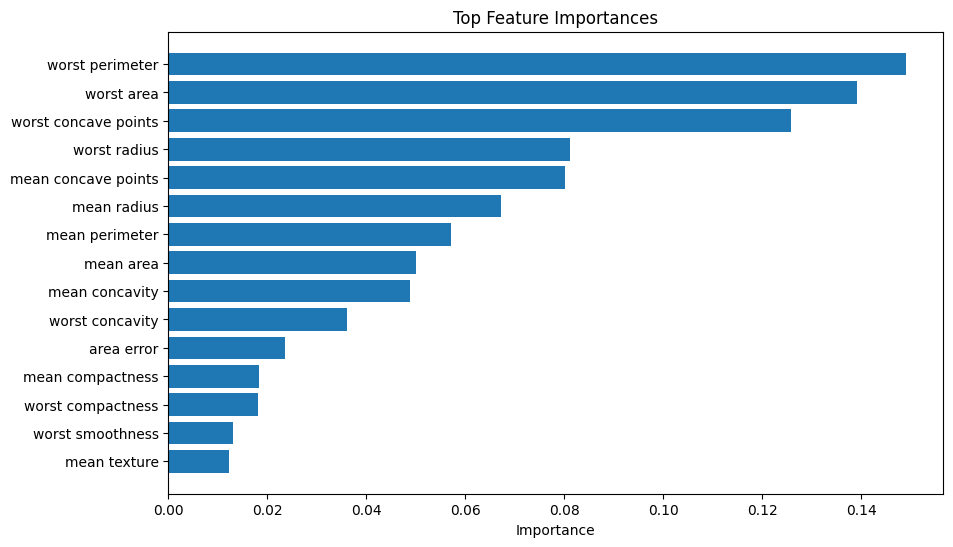

In [ ]:
plt.figure(figsize=(10, 6))

top_features = importance.head(15)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Top Feature Importances")
plt.xlabel("Importance")

plt.show()

In [ ]:
results_df
results_df = []

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]

    results_df.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1": f1_score(y_val, y_pred),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })

results_df = pd.DataFrame(results_df)
results_df

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.988235,1.000000,0.981132,0.990476,1.000000
1,KNN,0.988235,0.981481,1.000000,0.990654,0.995578
2,Naive Bayes,0.964706,0.980769,0.962264,0.971429,0.997642
3,Decision Tree,0.929412,0.979592,0.905660,0.941176,0.937205
4,Random Forest,0.988235,1.000000,0.981132,0.990476,1.000000
5,SVM,0.976471,1.000000,0.962264,0.980769,1.000000
6,Gradient Boosting,0.976471,0.981132,0.981132,0.981132,0.999410
7,XGBoost,0.988235,0.981481,1.000000,0.990654,1.000000
8,LightGBM,1.000000,1.000000,1.000000,1.000000,1.000000
9,CatBoost,0.988235,0.981481,1.000000,0.990654,1.000000
